# Анализ временных рядов: давление и расход

- Определение и удаление тренда и сезонности
- Построение авторегрессионной модели AR(p) и прогноз

In [2]:
# Импорты
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
import seaborn as sns

# Настройка графиков
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style("whitegrid")

In [3]:
# Загрузка данных
file_path = r'p_and_q_data.xlsx'

# Давление
df_pressure = pd.read_excel(file_path, sheet_name=0, engine='openpyxl')
pressure = df_pressure.iloc[:, 0].values
pressure = pressure[~np.isnan(pressure)]
time_p = np.arange(len(pressure)) * 4 # шаг 4 секунды

# Расход
df_flow = pd.read_excel(file_path, sheet_name=1, engine='openpyxl')
flow_raw = df_flow.iloc[:, 1].values
flow_q = flow_raw[~np.isnan(flow_raw)]
time_q = np.arange(len(flow_q)) * 2 # шаг 2 часа

## Давление: график и автокорреляция

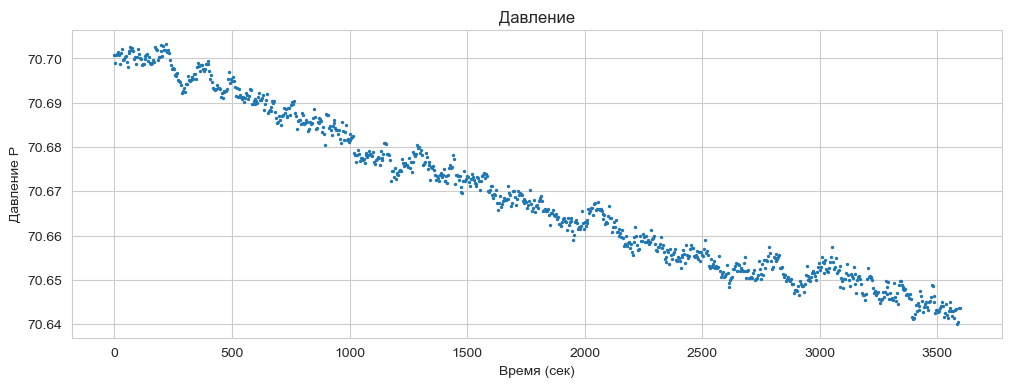

In [5]:
plt.figure(figsize=(12, 4))
plt.scatter(time_p, pressure, s=2)
plt.xlabel('Время (сек)')
plt.ylabel('Давление P')
plt.title('Давление')
plt.show()

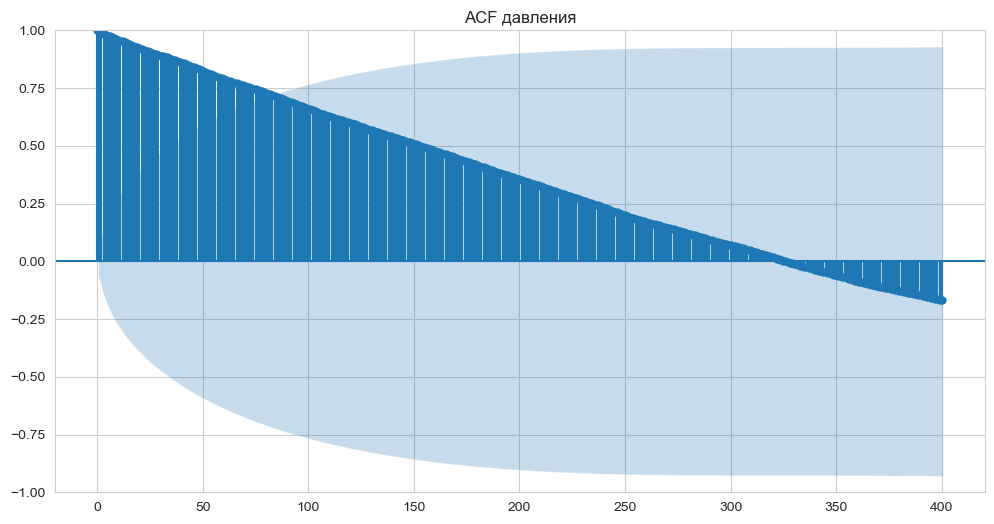

In [6]:
def autocor(x, max_lag):
    # автокорреляция
    n = len(x)
    x_mean = np.mean(x)
    c0 = np.sum((x - x_mean)**2)
    r = np.zeros(max_lag + 1)
    r[0] = 1.0
    for k in range(1, max_lag + 1):
        ck = np.sum((x[:n-k] - x_mean) * (x[k:] - x_mean))
        r[k] = ck / c0
    return r

max_lag = 400
acf_p = autocor(pressure, max_lag)
plot_acf(pressure, lags=max_lag, title='ACF давления')
plt.show()

## Приведение давления к стационарному виду

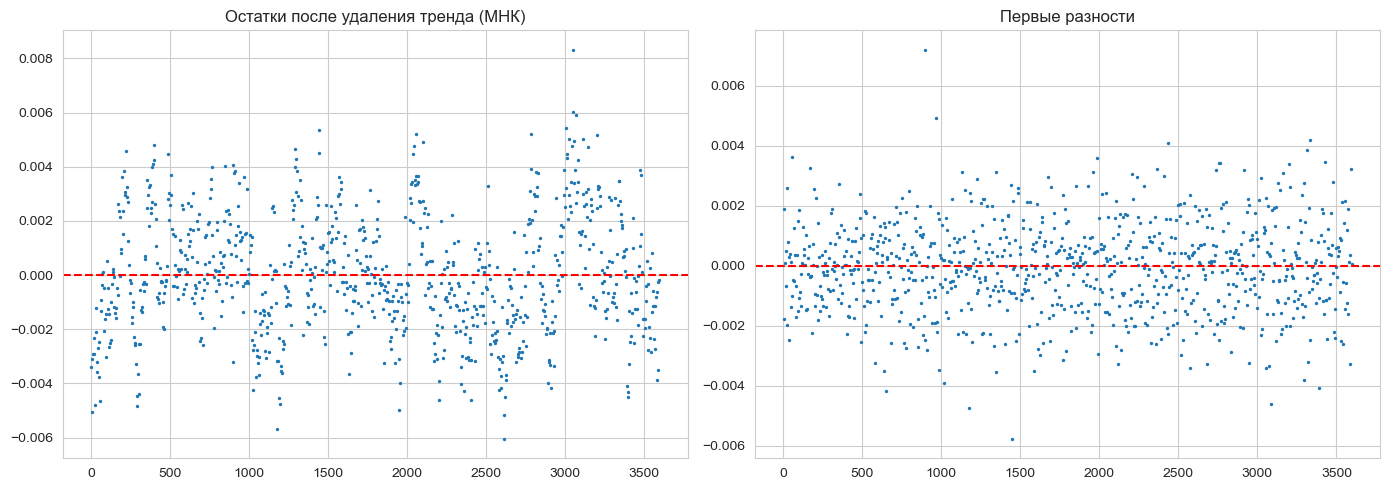

In [8]:
# Линейный тренд МНК
n = len(pressure)
X_trend = np.column_stack([np.ones(n), time_p, time_p**2])  # квадратичный тренд
b_trend = np.linalg.solve(X_trend.T @ X_trend, X_trend.T @ pressure)
trend_mnk = X_trend @ b_trend
resid_mnk = pressure - trend_mnk

# Метод разностей
delta_p = np.diff(pressure)

# Графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(time_p, resid_mnk, s=2)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Остатки после удаления тренда (МНК)')
axes[1].scatter(time_p[1:], delta_p, s=2)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Первые разности')
plt.tight_layout()
plt.show()

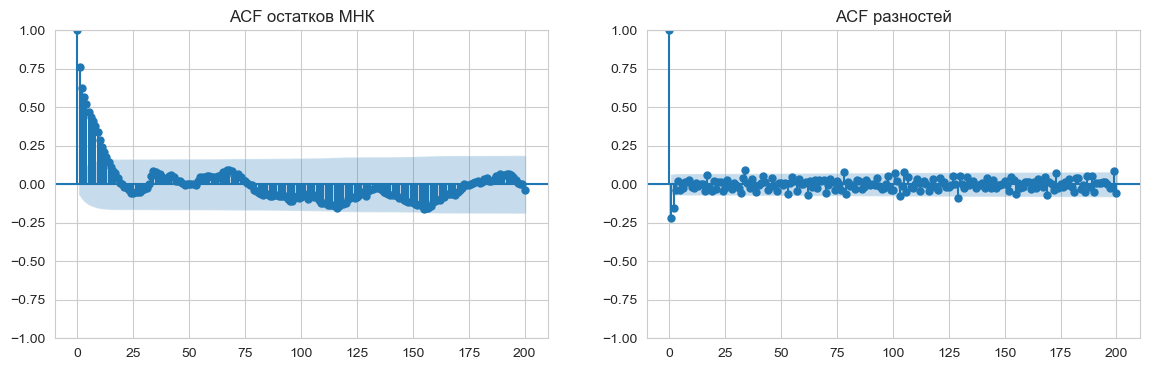

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(resid_mnk, lags=200, ax=axes[0], title='ACF остатков МНК')
plot_acf(delta_p, lags=200, ax=axes[1], title='ACF разностей')
plt.show()

## Критерий Дики–Фуллера для проверки стационарности для исходных данных

In [11]:
def d_f_test(series, model='ARD', alpha=0.05):
    """
    Тест Дики–Фуллера
    model: 'AR' (без константы и тренда), 'ARD' (с константой), 'TS' (с константой и трендом)
    """
    if model == 'AR':
        reg = 'n'
    elif model == 'ARD':
        reg = 'c'
    elif model == 'TS':
        reg = 'ct'
    
    result = adfuller(series, regression=reg, autolag='t-stat', store=True, regresults=True)
    adf_stat = result[0]
    p_val = result[1]
    crit_vals = result[2]
    res_obj = result[3]
    lags = res_obj.usedlag
    coefs = res_obj.resols.params
    stderrs = res_obj.resols.bse
    nobs = res_obj.nobs
    pvalues_coef = res_obj.resols.pvalues
    significance = {name: pvalues_coef[i] < alpha for i, name in enumerate(res_obj.resols.model.exog_names)}
    
    stationary = p_val < alpha
    conclusion = "Ряд стационарен (H0 отвергается)" if stationary else "Ряд нестационарен (H0 не отвергается)"
    
    print(f'Модель: {model}')
    print(f'ADF Statistic: {adf_stat:.4f}')
    print(f'p-value: {p_val:.4f}')
    print(f'Использовано лагов: {lags}')
    print('Критические значения:')
    for key, val in crit_vals.items():
        print(f'   {key}: {val:.4f}')
    print('Значимость коэффициентов (5%):')
    for var, signif in significance.items():
        print(f'   {var}: {"значим" if signif else "не значим"}')
    print(conclusion)
    return stationary

print("Исходный ряд давления:")
for model in ['AR', 'ARD', 'TS']:
    d_f_test(pressure, model=model)
    print()

Исходный ряд давления:
Модель: AR
ADF Statistic: -3.5846
p-value: 0.0004
Использовано лагов: 21
Критические значения:
   1%: -2.5683
   5%: -1.9413
   10%: -1.6165
Значимость коэффициентов (5%):
   x1: значим
   x2: значим
   x3: значим
   x4: значим
   x5: значим
   x6: значим
   x7: значим
   x8: не значим
   x9: не значим
   x10: не значим
   x11: не значим
   x12: не значим
   x13: не значим
   x14: не значим
   x15: не значим
   x16: не значим
   x17: значим
   x18: не значим
   x19: не значим
   x20: не значим
   x21: не значим
   x22: не значим
Ряд стационарен (H0 отвергается)

Модель: ARD
ADF Statistic: -1.1681
p-value: 0.6872
Использовано лагов: 21
Критические значения:
   1%: -3.4378
   5%: -2.8648
   10%: -2.5685
Значимость коэффициентов (5%):
   x1: не значим
   x2: значим
   x3: значим
   x4: значим
   x5: значим
   x6: значим
   x7: значим
   x8: не значим
   x9: не значим
   x10: не значим
   x11: не значим
   x12: не значим
   x13: не значим
   x14: не значим
   x15: не

## Расход: график, ACF и период

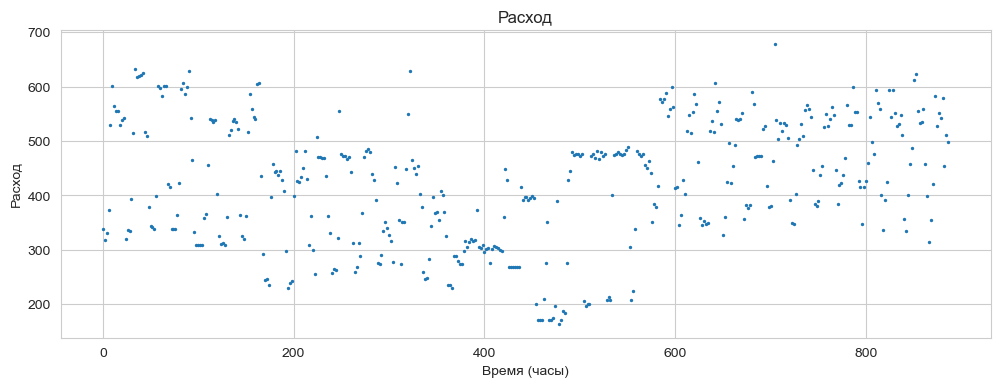

In [13]:
plt.figure(figsize=(12, 4))
plt.scatter(time_q, flow_q, s=2)
plt.xlabel('Время (часы)')
plt.ylabel('Расход')
plt.title('Расход')
plt.show()

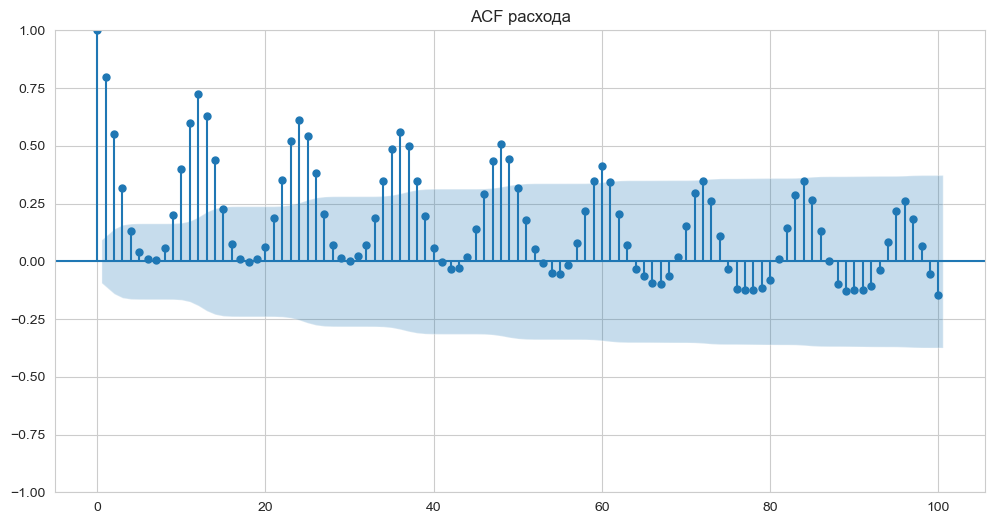

Период сезонности: 12 лагов = 24 часов


In [14]:
max_lag_q = 100
plot_acf(flow_q, lags=max_lag_q, title='ACF расхода')
plt.show()

# определение периода по максимуму ACF
acf_flow = autocor(flow_q, max_lag_q)
lags_arr = np.arange(len(acf_flow))
peaks = []
for i in range(5, len(acf_flow)-1):
    if acf_flow[i] > acf_flow[i-1] and acf_flow[i] > acf_flow[i+1]:
        peaks.append(i)

period_lag = peaks[0]
period_hours = period_lag * 2
print(f'Период сезонности: {period_lag} лагов = {period_hours} часов')

## Удаление тренда и сезонности

Дисперсии остатков после удаления сезонности:
Фурье: 4292.43
Индикаторные: 3059.91
Средние по часам: 3059.91
Сезонные разности: 4550.53


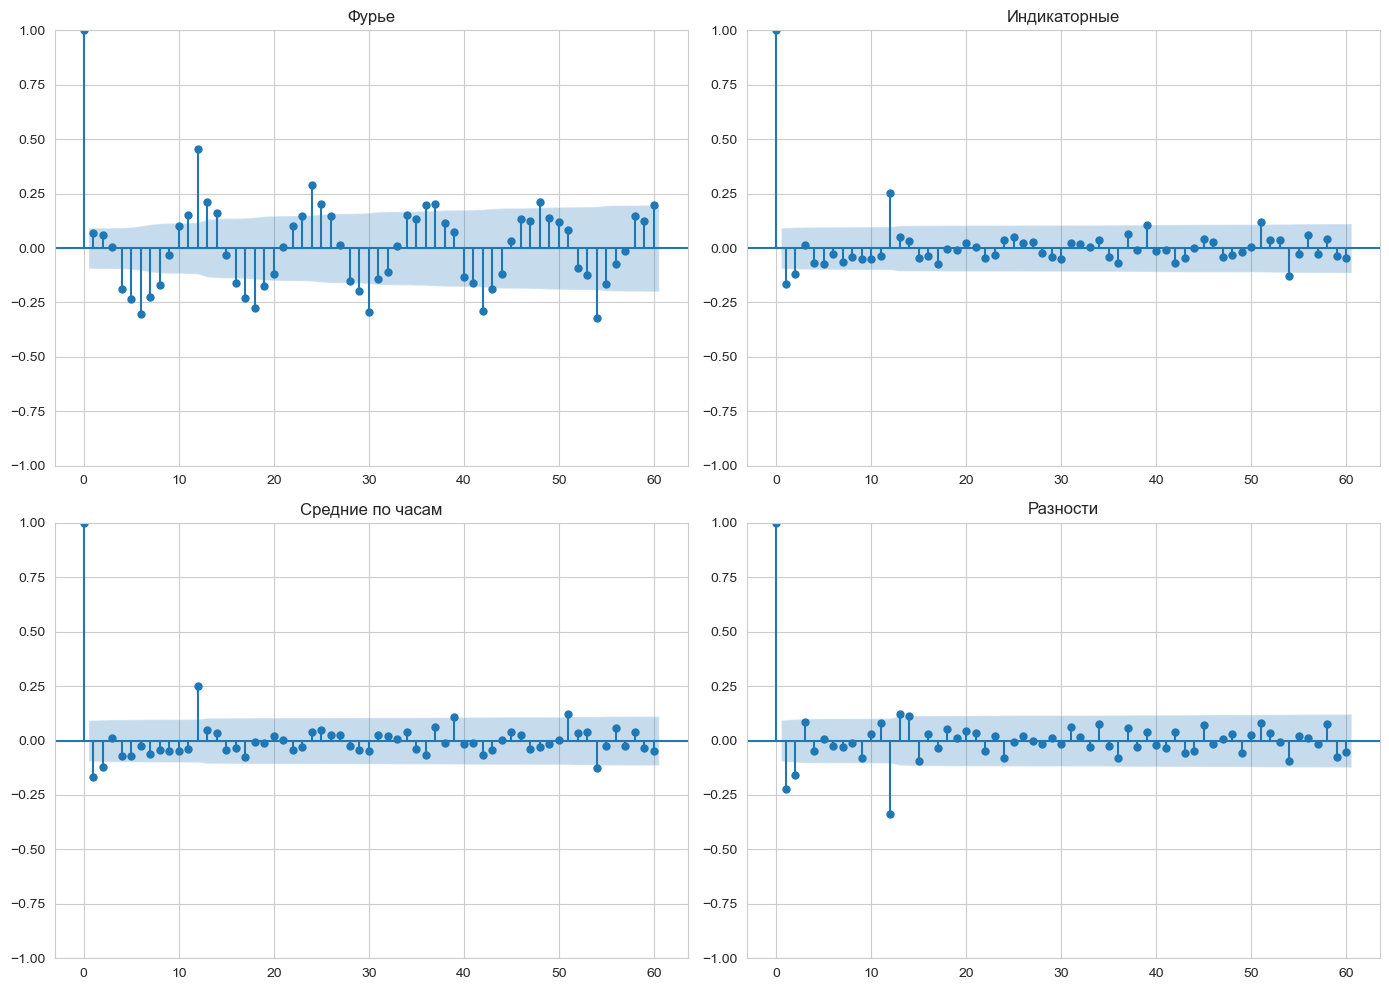

In [16]:
# Удаление тренда последовательными разностями
q_diff = np.diff(flow_q)
time_q_diff = time_q[1:]
T = period_lag

# 1. Фурье
def fourier_seasonal(y, period, time_idx):
    n = len(y)
    # const + sin(2*pi*k*t/T) и cos(2*pi*k*t/T) для k=1...(T//2 -1)
    basis = [np.ones(n)]
    for k in range(1, T//2):
        basis.append(np.sin(2 * np.pi * k * time_idx / period))
        basis.append(np.cos(2 * np.pi * k * time_idx / period))
    X = np.column_stack(basis)
    # МНК
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    trend = X @ b
    resid = y - trend
    return trend, resid

trend_four, resid_four = fourier_seasonal(q_diff, T, time_q_diff)

# 2. Индикаторные переменные для каждого 2‑часового интервала
hours_bin = (time_q_diff % 24) // 2  # 0-11
unique_hours = np.unique(hours_bin)
X_ind = np.zeros((len(q_diff), len(unique_hours)))
for i, h in enumerate(unique_hours):
    X_ind[hours_bin == h, i] = 1
b_ind = np.linalg.lstsq(X_ind, q_diff, rcond=None)[0]
trend_ind = X_ind @ b_ind
resid_ind = q_diff - trend_ind

# 3. Средние по каждому интервалу в 2 часа
hourly_means = {h: np.mean(q_diff[hours_bin == h]) for h in unique_hours}
trend_mean = np.array([hourly_means[h] for h in hours_bin])
resid_mean = q_diff - trend_mean

# 4. разности
q_season = q_diff[T:] - q_diff[:-T]

# Сравнение дисперсий остатков
print('Дисперсии остатков после удаления сезонности:')
print(f'Фурье: {np.var(resid_four):.2f}')
print(f'Индикаторные: {np.var(resid_ind):.2f}')
print(f'Средние по часам: {np.var(resid_mean):.2f}')
print(f'Сезонные разности: {np.var(q_season):.2f}')

# Графики ACF остатков
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_acf(resid_four, lags=60, ax=axes[0,0], title='Фурье')
plot_acf(resid_ind, lags=60, ax=axes[0,1], title='Индикаторные')
plot_acf(resid_mean, lags=60, ax=axes[1,0], title='Средние по часам')
plot_acf(q_season, lags=60, ax=axes[1,1], title='Разности')
plt.tight_layout()
plt.show()

## Подбор порядка AR(p) для давления

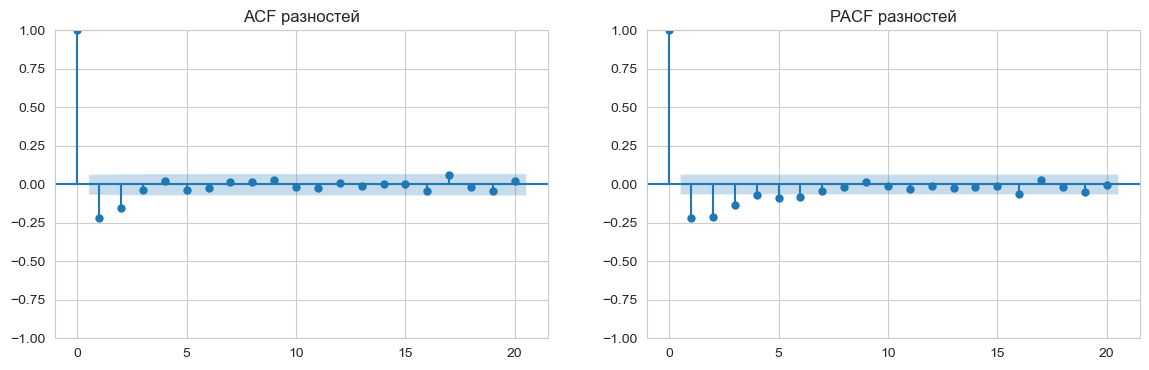

In [18]:
max_lags_ar = 20
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(delta_p, lags=max_lags_ar, ax=axes[0], title='ACF разностей')
plot_pacf(delta_p, lags=max_lags_ar, ax=axes[1], title='PACF разностей', method='ywm')
plt.show()

Последний значимый коэффициент при p = 6


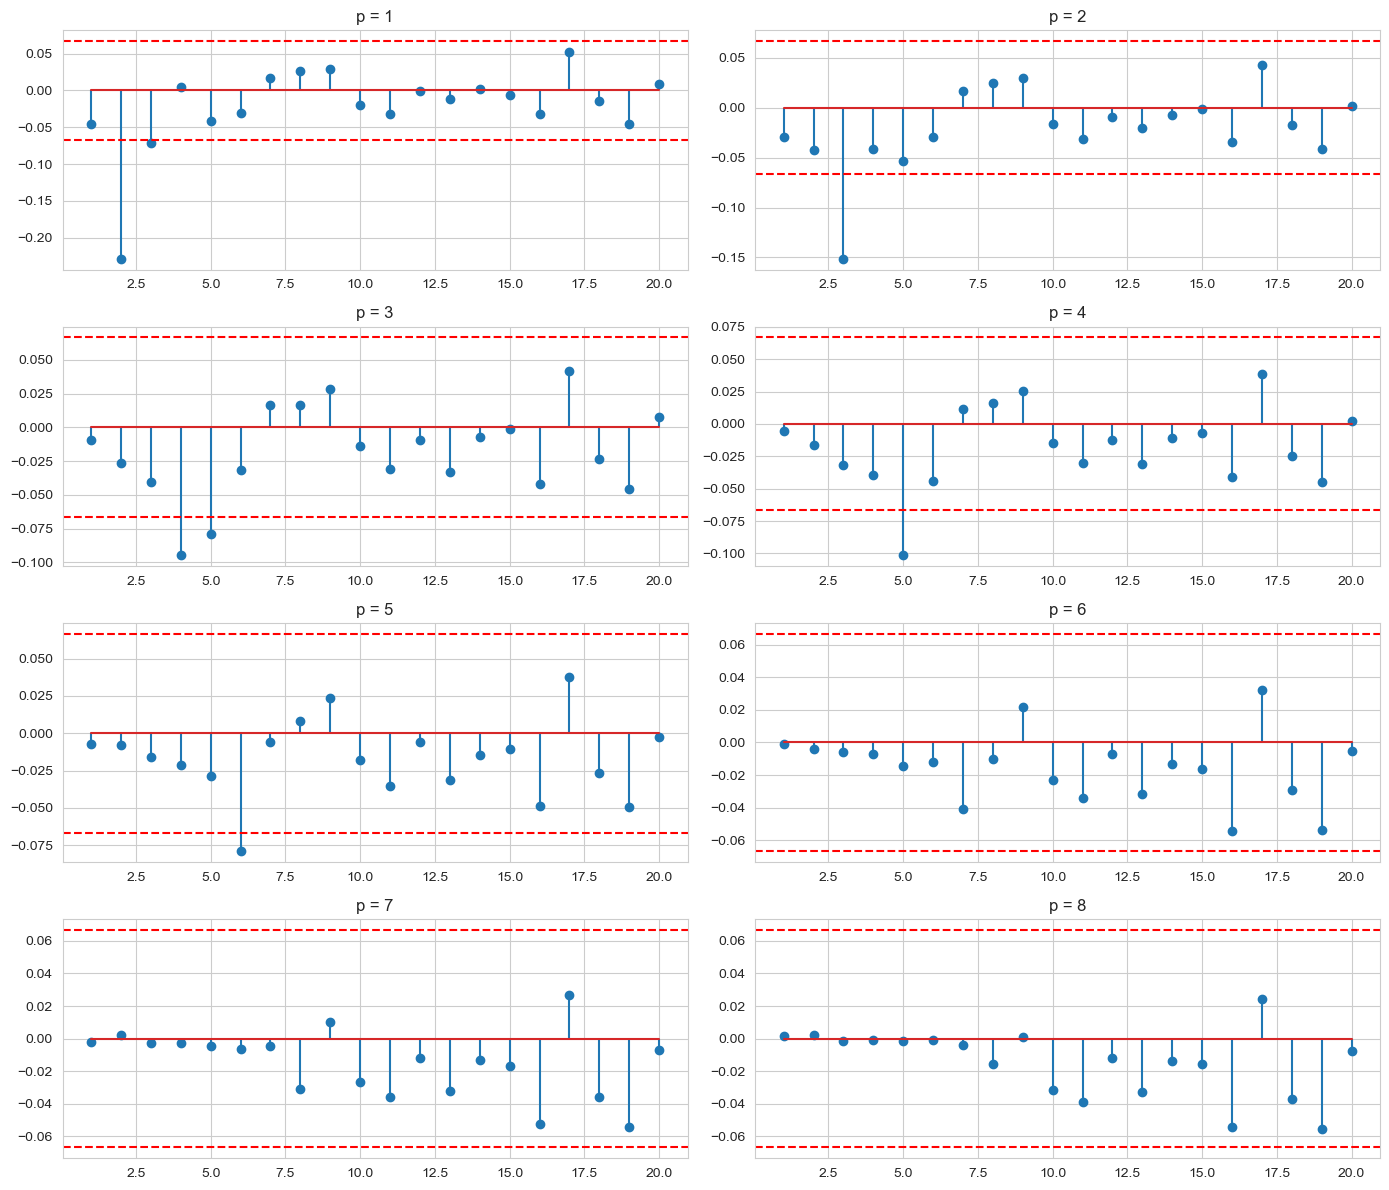

Наименьший допустимый порядок по ACF остатков: p = 6


In [19]:
def ar_matrix(y, p):
    """Создание матрицы для AR(p) с константой"""
    n = len(y)
    X = np.ones((n - p, p + 1))
    for i in range(p):
        X[:, i+1] = y[p-1-i : n-1-i]
    return X, y[p:]

def mnk_ar(X, y):
    """МНК оценка"""
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    y_pred = X @ b
    e = y - y_pred
    n, m = X.shape
    sigma2 = np.sum(e**2) / (n - m)
    # Ковариационная матрица
    XtX_inv = np.linalg.inv(X.T @ X)
    se = np.sqrt(sigma2 * np.diag(XtX_inv))
    t_stat = b / se
    p_val = 2 * (1 - stats.t.cdf(np.abs(t_stat), n - m))
    return b, e, sigma2, p_val, n, m

max_p = 20
significance_last = []
for p in range(1, max_p + 1):
    X, y = ar_matrix(delta_p, p)
    b, e, s2, pvals, n, m = mnk_ar(X, y)
    significance_last.append(pvals[-1] < 0.05)  # значимость последнего коэффициента

last_significant = np.where(significance_last)[0][-1] + 1 if any(significance_last) else 0
print(f'Последний значимый коэффициент при p = {last_significant}')

# ACF остатков для p от 1 до 8
intrv = 2 / np.sqrt(len(delta_p))
fig, axes = plt.subplots(4, 2, figsize=(14, 12))
min_ok_p = None
for idx, p in enumerate(range(1, 9)):
    X, y = ar_matrix(delta_p, p)
    b, e, _, _, _, _ = mnk_ar(X, y)
    ax = axes[idx // 2, idx % 2]
    ax.stem(range(1, 21), autocor(e, 20)[1:21])
    ax.axhline(intrv, color='red', linestyle='--')
    ax.axhline(-intrv, color='red', linestyle='--')
    ax.set_title(f'p = {p}')
    if min_ok_p is None and np.all(np.abs(autocor(e, 20)[1:]) < intrv):
        min_ok_p = p
plt.tight_layout()
plt.show()
print(f'Наименьший допустимый порядок по ACF остатков: p = {min_ok_p}')

## Прогноз на 10 минут

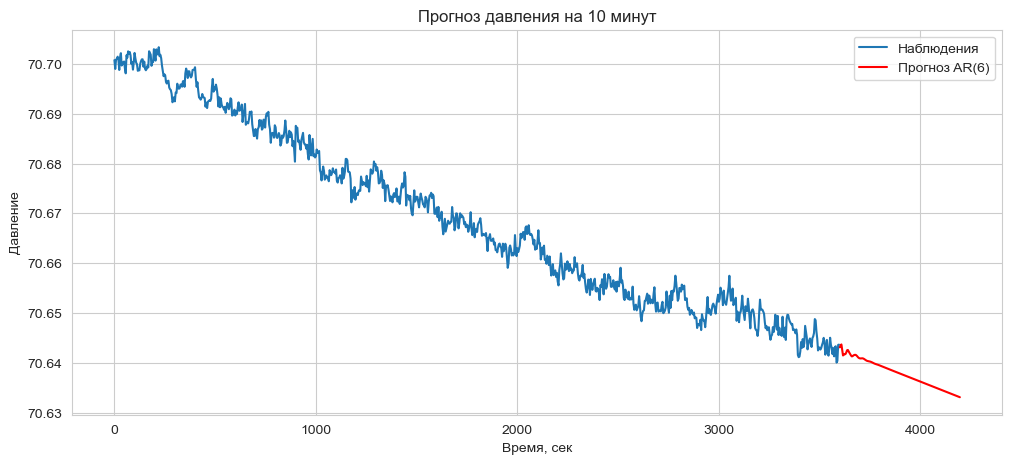

In [21]:
p_best = 6   # выбранный порядок
k_forecast = 150   # 10 мин / 4 сек = 150

# Окончательная модель
X, y = ar_matrix(delta_p, p_best)
b, _, _, _, _, _ = mnk_ar(X, y)

# Прогноз разностей
last_values = list(delta_p[-p_best:])
forecast_delta = []
for _ in range(k_forecast):
    val = b[0] + np.dot(b[1:], last_values[-p_best:])
    forecast_delta.append(val)
    last_values.append(val)

# Прогноз давления
pressure_forecast = [pressure[-1]]
for d in forecast_delta:
    pressure_forecast.append(pressure_forecast[-1] + d)

time_forecast = [time_p[-1] + (i+1)*4 for i in range(k_forecast)]

# График
plt.figure(figsize=(12, 5))
plt.plot(time_p, pressure, label='Наблюдения')
plt.plot(time_forecast, pressure_forecast[1:], label='Прогноз AR(6)', color='red')
plt.legend()
plt.title('Прогноз давления на 10 минут')
plt.xlabel('Время, сек')
plt.ylabel('Давление')
plt.show()